In [1]:
%load_ext autoreload
%autoreload 2

from fxml import config
from fxml.datasets.table import build_vol_table
from fxml.db.connection import connect
from fxml.db.repository import load_bars

bars = load_bars(connect(), "EURUSD", "H1", start=config.TRAIN_START)
vol_table = build_vol_table(bars, horizon=config.VOL_HORIZON)
print(len(vol_table), "rows:", vol_table.index.min(), "->", vol_table.index.max())
vol_table.corr(method="spearman")["target_log_vol"].sort_values()


72851 rows: 2015-02-02 03:00:00+00:00 -> 2026-10-15 19:00:00+00:00


dow_cos          -0.087796
hour_sin         -0.001159
hour_cos          0.003542
vol_rel           0.029092
dow_sin           0.052478
log_range         0.335192
log_rv_6          0.359833
log_rv_24         0.518545
log_rv_120        0.599652
log_atr           0.603248
log_rv_500        0.607719
target_log_vol    1.000000
Name: target_log_vol, dtype: float64

In [2]:
from fxml.datasets.splits import walk_forward_splits
from fxml.evaluation import plots
from fxml.training.baselines import walk_forward_forecast, walk_forward_persistence
import pandas as pd
from fxml.features.volatility import VOL_FEATURE_COLUMNS


plots.apply_style()
folds = walk_forward_splits(len(vol_table), train_size=31_000, test_size=3_100,
                            gap=config.VOL_HORIZON)
HAR_COLUMNS = ["log_rv_6", "log_rv_24", "log_rv_120", "log_rv_500"]

persistence = walk_forward_persistence(vol_table, folds, "log_rv_24")
har = walk_forward_forecast(vol_table, folds, HAR_COLUMNS)
har_plus = walk_forward_forecast(vol_table, folds, VOL_FEATURE_COLUMNS)

r2 = pd.DataFrame({"persistence": persistence["r2"], "HAR": har["r2"], "HAR+": har_plus["r2"]})
print(len(folds), "folds")
r2.round(3)


13 folds


,persistence,HAR,HAR+
fold,,,
1,0.422,0.487,0.573
2,-0.243,0.221,0.181
3,-0.026,0.432,0.447
4,0.288,0.561,0.570
5,0.319,0.503,0.541
6,0.404,0.632,0.653
7,-0.642,0.032,0.105
8,-0.824,-0.010,0.027
9,0.065,0.437,0.501


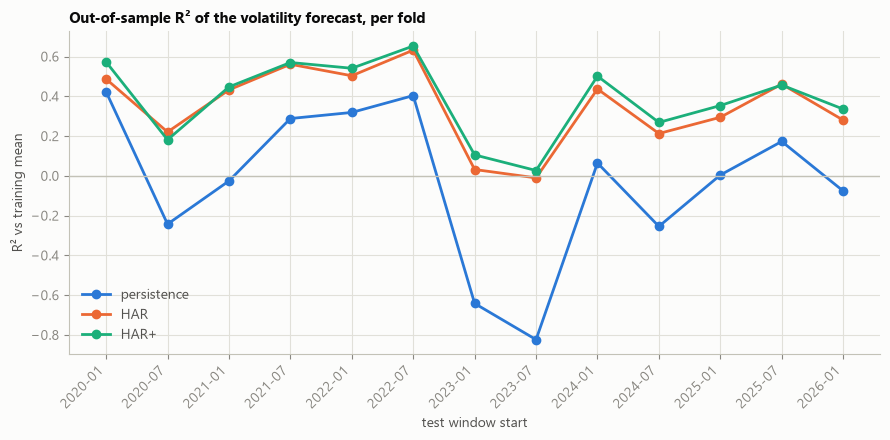

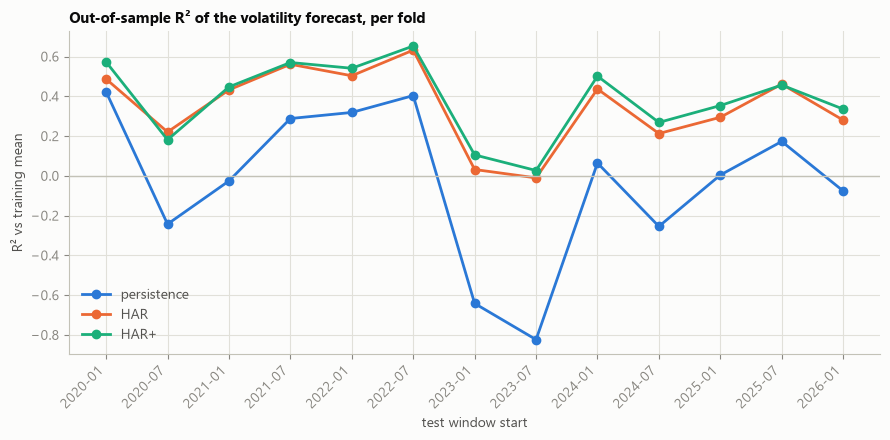

In [3]:
labels = [t.strftime("%Y-%m") for t in har["test_from"]]
plots.fold_lines(r2, labels, "Out-of-sample R² of the volatility forecast, per fold",
                 "R² vs training mean")


In [4]:
print(f"mean R²: persistence {r2['persistence'].mean():.3f}, HAR {r2['HAR'].mean():.3f}, HAR+ {r2['HAR+'].mean():.3f}")
print(f"HAR beats persistence in {(r2['HAR'] > r2['persistence']).sum()} of {len(r2)} folds (need 11 of 13, and mean R² > 0.3)")
print(f"HAR+ beats HAR in {(r2['HAR+'] > r2['HAR']).sum()} of {len(r2)} folds")


mean R²: persistence -0.030, HAR 0.350, HAR+ 0.386
HAR beats persistence in 13 of 13 folds (need 11 of 13, and mean R² > 0.3)
HAR+ beats HAR in 11 of 13 folds


40300 out-of-sample forecasts; correlation 0.651


<Axes: title={'left': 'Weekly average: forecast vs actual log-vol'}, xlabel='time'>

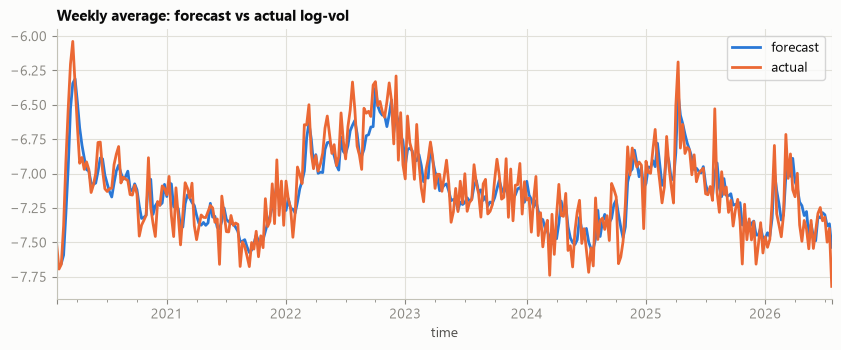

In [5]:
from fxml.training.baselines import walk_forward_predict

forecast = walk_forward_predict(vol_table, folds, VOL_FEATURE_COLUMNS)
check = pd.DataFrame({"forecast": forecast,
                      "actual": vol_table.loc[forecast.index, "target_log_vol"]})
print(len(check), "out-of-sample forecasts; correlation", round(check.corr().iloc[0, 1], 3))
check.resample("W").mean().plot(figsize=(10, 3.5), color=[plots.BLUE, plots.ORANGE],
                                title="Weekly average: forecast vs actual log-vol")
